**Setup**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys, importlib
REPO = "/content/anomaly-mvtec"
if not os.path.exists(REPO):
    !git clone https://github.com/maha-mrrk/anomaly-mvtec.git {REPO}
else:
    !git -C {REPO} pull
%cd {REPO}
if REPO not in sys.path:
    sys.path.append(REPO)
importlib.invalidate_caches()          # prend en compte les nouveaux fichiers après un pull
!pip install -q -r requirements.txt

from src.config import *
set_seed(42)
prepare_data()
print(device, DATA_ROOT)

Mounted at /content/drive
Cloning into '/content/anomaly-mvtec'...
remote: Enumerating objects: 21, done.
remote: Counting objects: 100% (21/21), done.
remote: Compressing objects: 100% (15/15), done.
remote: Total 21 (delta 7), reused 16 (delta 5), pack-reused 0 (from 0)
Receiving objects: 100% (21/21), 5.84 KiB | 1.17 MiB/s, done.
Resolving deltas: 100% (7/7), done.
/content/anomaly-mvtec
Données prêtes : ['carpet', 'screw', 'cable']
cuda /content/mvtec


**Structure**

In [3]:
!find {DATA_ROOT}/screw -maxdepth 2 | head -30

/content/mvtec/screw
/content/mvtec/screw/train
/content/mvtec/screw/train/good
/content/mvtec/screw/ground_truth
/content/mvtec/screw/ground_truth/thread_top
/content/mvtec/screw/ground_truth/scratch_head
/content/mvtec/screw/ground_truth/scratch_neck
/content/mvtec/screw/ground_truth/manipulated_front
/content/mvtec/screw/ground_truth/thread_side
/content/mvtec/screw/test
/content/mvtec/screw/test/thread_top
/content/mvtec/screw/test/scratch_head
/content/mvtec/screw/test/good
/content/mvtec/screw/test/scratch_neck
/content/mvtec/screw/test/manipulated_front
/content/mvtec/screw/test/thread_side
/content/mvtec/screw/license.txt
/content/mvtec/screw/readme.txt


**effectifs des splits**

In [4]:
from src.data import *
for cat in CATEGORIES:
    tr, val = list_train_val(DATA_ROOT, cat)
    te = list_test(DATA_ROOT, cat)
    print(f"{cat:7s} train={len(tr):4d}  val_normal={len(val):3d}  "
          f"test={len(te):4d}  dont défauts={sum(l for _, l, _ in te)}")

carpet  train= 224  val_normal= 56  test= 117  dont défauts=89
screw   train= 256  val_normal= 64  test= 160  dont défauts=119
cable   train= 180  val_normal= 44  test= 150  dont défauts=92


**visualisation pour les 3 catégories**

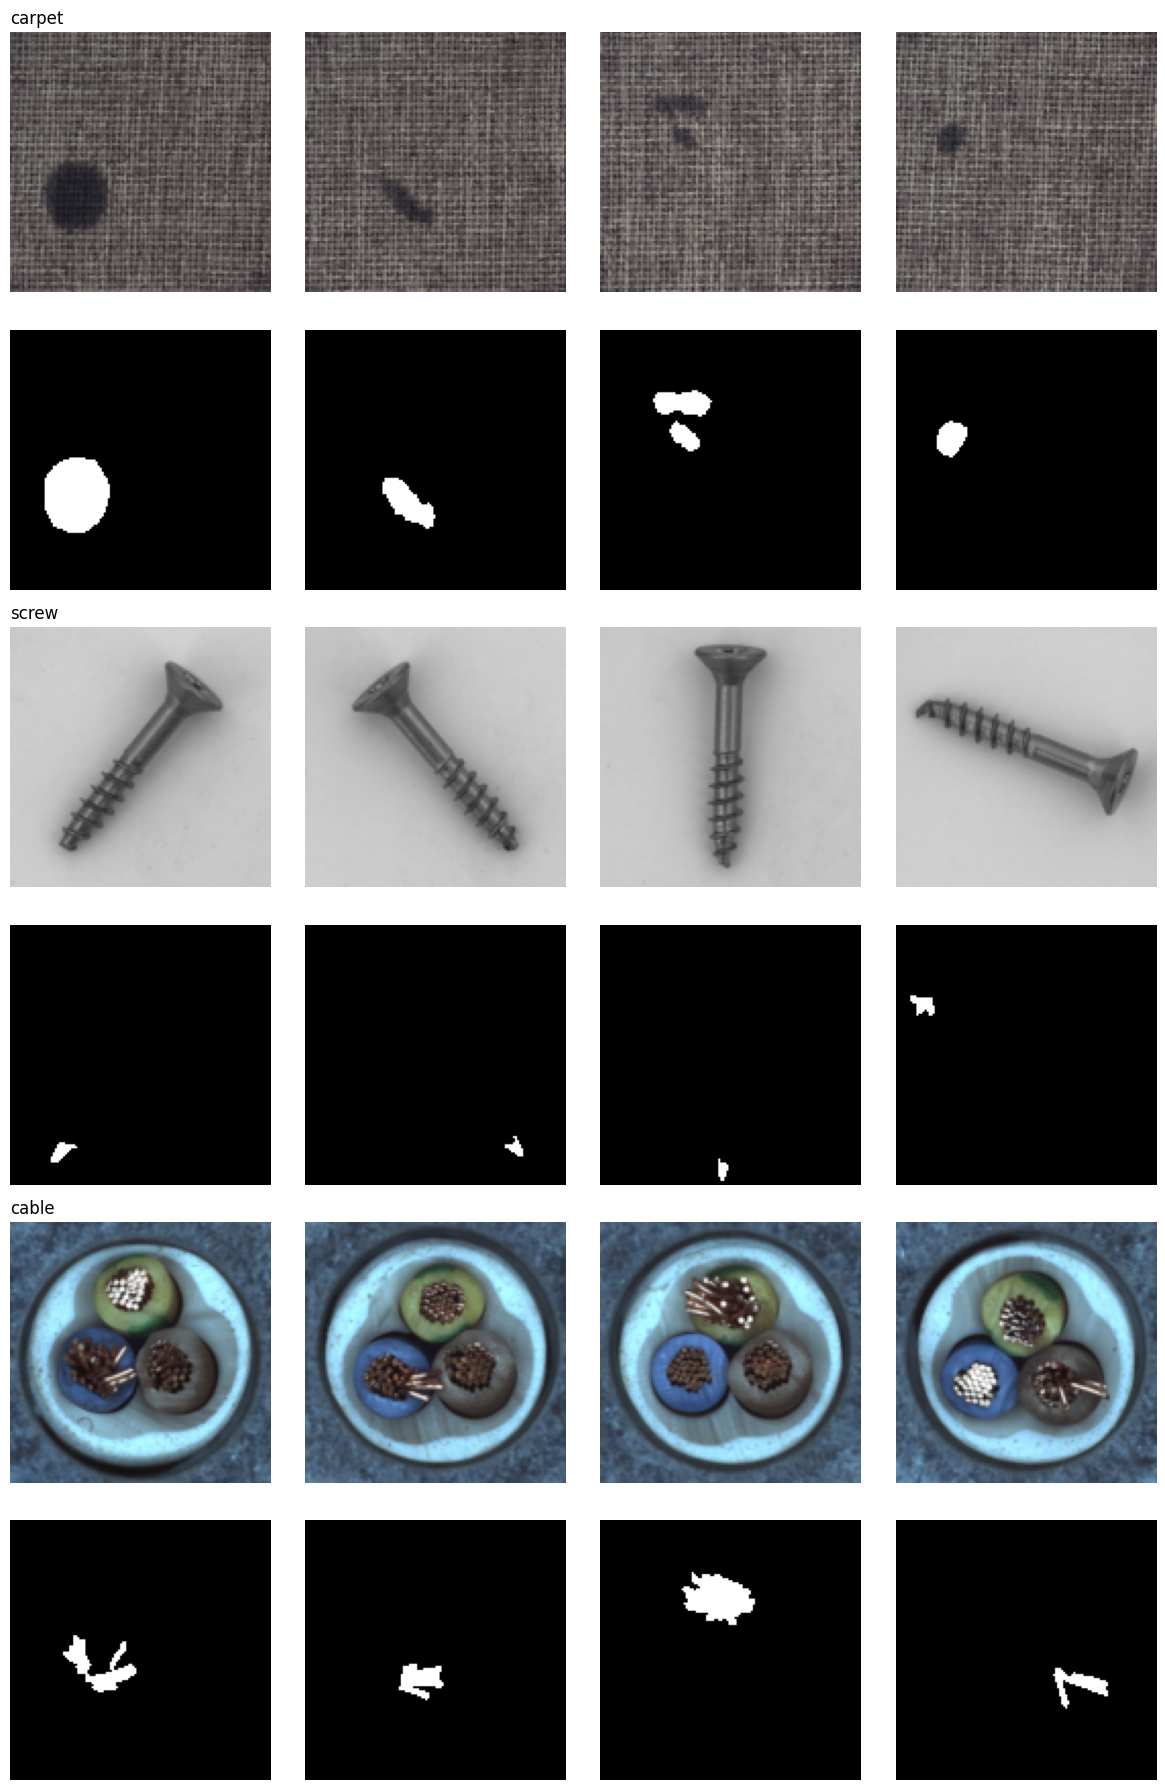

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(6, 4, figsize=(12, 18))
for c, cat in enumerate(CATEGORIES):
    ds = MVTecDataset(list_test(DATA_ROOT, cat), img_size=128)
    bad = [i for i, (_, l, _) in enumerate(ds.items) if l == 1][:4]
    for k, i in enumerate(bad):
        img, lab, mask = ds[i]
        ax[2*c, k].imshow(img.permute(1, 2, 0));  ax[2*c, k].axis("off")
        ax[2*c+1, k].imshow(mask[0], cmap="gray"); ax[2*c+1, k].axis("off")
    ax[2*c, 0].set_title(cat, loc="left")
plt.tight_layout(); plt.show()